# Jetsound: Sound detection with Jetson Nano

## Data collection and feature extraction

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
import librosa

#DATADIR = 'music_dataset'
DATADIR = "../Haakons_testfolder/instrument_set"
print(DATADIR)
CATEGORIES = ['Acoustic_guitar', 'Drum_set', 'vibraphone']

../Haakons_testfolder/instrument_set


Function to make spectrograms.

In [5]:
def convert_to_spectrogram(audio_signal, sample_rate, n_mels, fmax=8000):
    # audio_signal
    # sample_rate
    # n_mels : mels bins (Y-resolution of spectrogram)
    # fmax : maximum frequency in spectrogram

    # Returns a 4D tensorflow tensor (1, n_mels, time_steps, 1)
        
    # Create mel spectrogram
    mel_spec = librosa.feature.melspectrogram(
        y = audio_signal,
        sr = sample_rate,
        n_mels = n_mels,
        fmax = fmax
    )
    
    # Convert to decibels
    mel_spec = librosa.power_to_db(mel_spec, ref=np.max)

    # Normalize
    mel_spec = (mel_spec - mel_spec.min()) / (mel_spec.max() - mel_spec.min())

    # Add channel dimension
    return mel_spec[..., np.newaxis]  # shape: (n_mels, time_steps, 1)

    # Add batch dimension
    #return mel_spec[np.newaxis, ...]

In [6]:
dataset = []
N_MELS = 128 # Y resolution of the spectrograms (basically image height)
T_SAMP = 300 # X resolution of the spectrograms (basically image width)

def create_dataset(limit):
    for category in CATEGORIES:
        path = os.path.join(DATADIR, category)
        class_num = CATEGORIES.index(category) #Assigns category 0 to Autistic_guitar, 1 to Drum_set and 2 to vibraphone
        for audio_sample in os.listdir(path):
            if len(dataset)>limit:
                break
            try:
                audio, sr = librosa.load(os.path.join(path, audio_sample))
                spectro = convert_to_spectrogram(audio, sr, N_MELS, fmax=8000)
                dataset.append([spectro, class_num, sr]) # Appends the category to the array
                print(audio_sample)
            except Exception as e:
                pass
    
create_dataset(5000)

print(len(dataset))

1.wav
10.wav
100.wav
101.wav
102.wav
103.wav
104.wav
105.wav
106.wav
107.wav
108.wav
109.wav
11.wav
110.wav
111.wav
112.wav
113.wav
114.wav
115.wav
116.wav
117.wav
118.wav
119.wav
12.wav
120.wav
121.wav
122.wav
123.wav
124.wav
125.wav
126.wav
127.wav
128.wav
129.wav
13.wav
130.wav
131.wav
132.wav
133.wav
134.wav
135.wav
136.wav
137.wav
138.wav
139.wav
14.wav
140.wav
141.wav
142.wav
143.wav
144.wav
145.wav
146.wav
147.wav
148.wav
149.wav
15.wav
150.wav
151.wav
152.wav
153.wav
154.wav
155.wav
156.wav
157.wav
158.wav
159.wav
16.wav
160.wav
161.wav
162.wav
163.wav
164.wav
165.wav
166.wav
167.wav
168.wav
169.wav
17.wav
170.wav
171.wav
172.wav
173.wav
174.wav
175.wav
176.wav
177.wav
178.wav
179.wav
18.wav
180.wav
181.wav
182.wav
183.wav
184.wav
185.wav
186.wav
187.wav
188.wav
189.wav
19.wav
190.wav
191.wav
192.wav
193.wav
194.wav
195.wav
196.wav
197.wav
198.wav
199.wav
2.wav
20.wav
200.wav
201.wav
202.wav
203.wav
204.wav
205.wav
206.wav
207.wav
208.wav
209.wav
21.wav
210.wav
211.wav
212.wav


Show example from new dataset


Number of mel bins (n_mels): 128
Number of samples (time-steps) in one entry: 130
Category: Acoustic_guitar


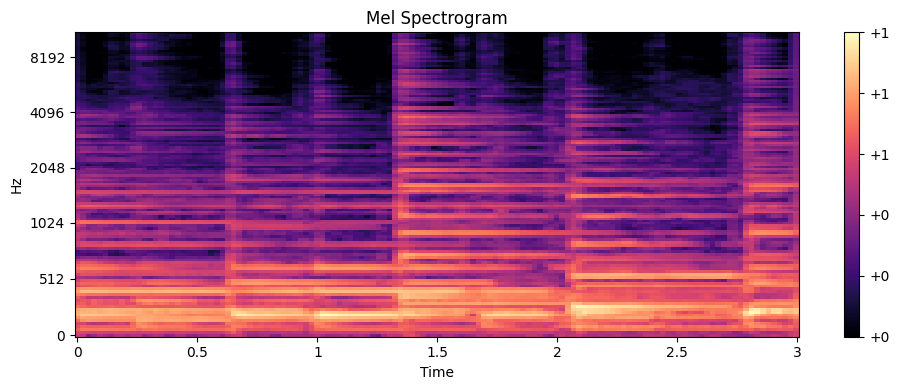

In [7]:
CHOSEN_EXAMPLE = 141

spec_tensor = dataset[CHOSEN_EXAMPLE][0]  # shape: ( n_mels, time_steps, 1)
n_mels, time_steps, channels = spec_tensor.shape
print("Number of mel bins (n_mels):", n_mels)
print("Number of samples (time-steps) in one entry:", time_steps)
print("Category: " + CATEGORIES[dataset[CHOSEN_EXAMPLE][1]])

# Remove batch and channel dimensions
spec = dataset[CHOSEN_EXAMPLE][0]
spec = spec[:, :, 0]

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    spec,
    x_axis="time",
    y_axis="mel",
    sr=dataset[CHOSEN_EXAMPLE][2]
)
plt.colorbar(format="%+2.0f")
plt.title("Mel Spectrogram")
plt.tight_layout()
plt.show()

Shuffle the dataset and make sure by looking at the labels.

In [ ]:
import random

random.shuffle(dataset)

# choose an arbitrary size and truncate
MAX_SAMPLES = 9000
dataset = dataset[:MAX_SAMPLES]
print(f"Shuffled and truncated dataset to {len(dataset)} samples.")

for sample in dataset[:10]:
    print(sample[1])

Shuffled and truncated dataset to 300 samples.
0
0
2
2
2
1
2
0
1
0


Create your train and test split.

x[141] shape: (128, 130, 1)
y[141]: 1 (category: Drum_set)
spec shape: (128, 130), min: 0.0000, max: 1.0000


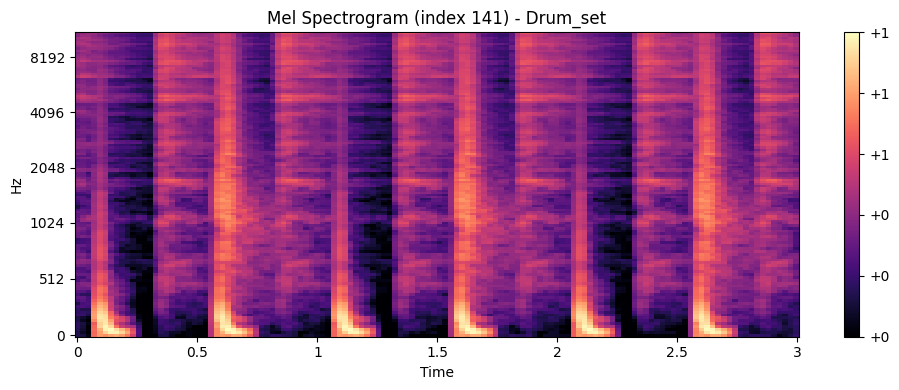

In [9]:
x = [] #Images
y = [] #Labels

for spectrogram, label, samplerate in dataset:
    x.append(spectrogram)  #Place all images in x
    y.append(label)     #Place all labels in y

x = np.array(x)
y = np.array(y)

##### Sanity check #####
# Print one example from x and y and visualize it
idx = 141
print(f"x[{idx}] shape: {x[idx].shape}")
print(f"y[{idx}]: {y[idx]} (category: {CATEGORIES[y[idx]]})")

# Remove batch and channel dimensions and show stats
spec = np.squeeze(x[idx])  # shape -> (n_mels, time_steps)
print(f"spec shape: {spec.shape}, min: {spec.min():.4f}, max: {spec.max():.4f}")

plt.figure(figsize=(10, 4))
librosa.display.specshow(spec, x_axis="time", y_axis="mel", sr=dataset[idx][2])
plt.colorbar(format="%+2.0f")
plt.title(f"Mel Spectrogram (index {idx}) - {CATEGORIES[y[idx]]}")
plt.tight_layout()
plt.show()
########################

# We have to split the data for testing
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.1, random_state=42)

## Network architecture

## Model training

In [22]:
# Model definition (simplified & regularized)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

weight_decay = 1e-4

model = Sequential([
    # Two smaller conv blocks (reduces capacity)
    Conv2D(32, (3,3), activation='relu', kernel_regularizer=l2(weight_decay), input_shape=x_train.shape[1:]),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu', kernel_regularizer=l2(weight_decay)),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    Flatten(),

    # Stepped-down dense layers instead of jumping directly 128 -> 3
    Dense(64, activation='relu', kernel_regularizer=l2(weight_decay)),
    BatchNormalization(),
    Dropout(0.5),

    Dense(32, activation='relu', kernel_regularizer=l2(weight_decay)),
    BatchNormalization(),
    Dropout(0.5),

    Dense(len(CATEGORIES), activation='softmax')
])

# Use a smaller learning rate to stabilise training
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

C:\Users\Test\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 126, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 62, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 61, 62, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 59520)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     3,809,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,831,107 (14.61 MB)

 Trainable params: 3,830,723 (14.61 MB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/10


9/9 - 6s - 674ms/step - accuracy: 0.6704 - loss: 0.7791 - val_accuracy: 0.7000 - val_loss: 0.9978 - learning_rate: 1.0000e-04
Epoch 2/10
9/9 - 3s - 323ms/step - accuracy: 0.8037 - loss: 0.5850 - val_accuracy: 0.5667 - val_loss: 1.0047 - learning_rate: 1.0000e-04
Epoch 3/10
9/9 - 3s - 338ms/step - accuracy: 0.8185 - loss: 0.4735 - val_accuracy: 0.8333 - val_loss: 1.0104 - learning_rate: 1.0000e-04
Epoch 4/10
9/9 - 3s - 346ms/step - accuracy: 0.8481 - loss: 0.4122 - val_accuracy: 0.9333 - val_loss: 1.0330 - learning_rate: 1.0000e-04
Epoch 5/10
9/9 - 3s - 358ms/step - accuracy: 0.8815 - loss: 0.3485 - val_accuracy: 0.3000 - val_loss: 1.0481 - learning_rate: 5.0000e-05
Epoch 6/10
9/9 - 3s - 336ms/step - accuracy: 0.9037 - loss: 0.3196 - val_accuracy: 0.3333 - val_loss: 1.0531 - learning_rate: 5.0000e-05
Epoch 7/10
9/9 - 3s - 338ms/step - accuracy: 0.8889 - loss: 0.3130 - val_accuracy: 0.4333 - val_loss: 1.0399 - learning_rate: 5.0000e-05
Epoch 8/10
9/9 - 3s - 323ms/step - accuracy: 0.8889 

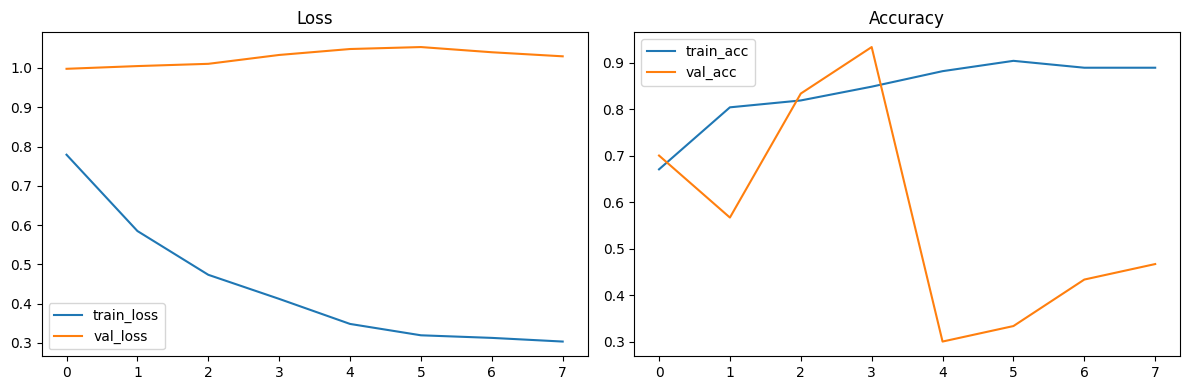

In [23]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

# Training config
EPOCHS = 10
checkpoint_cb = ModelCheckpoint('best_model.h5', save_best_only=True, monitor='val_loss', mode='min')
earlystop_cb = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
reduce_lr_cb = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)

history = model.fit(
    x_train, y_train,
    epochs=EPOCHS,
    #batch_size=batch,
    validation_data=(x_test, y_test),
    callbacks=[checkpoint_cb, earlystop_cb, reduce_lr_cb],
    verbose=2
)

# Evaluate and save final model
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"Test loss: {test_loss:.4f}, Test accuracy: {test_acc:.4f}")
#model.save("final_model.h5")

# Plot training history
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.legend(); plt.title('Loss')

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train_acc')
plt.plot(history.history['val_accuracy'], label='val_acc')
plt.legend(); plt.title('Accuracy')

plt.tight_layout()
plt.show()

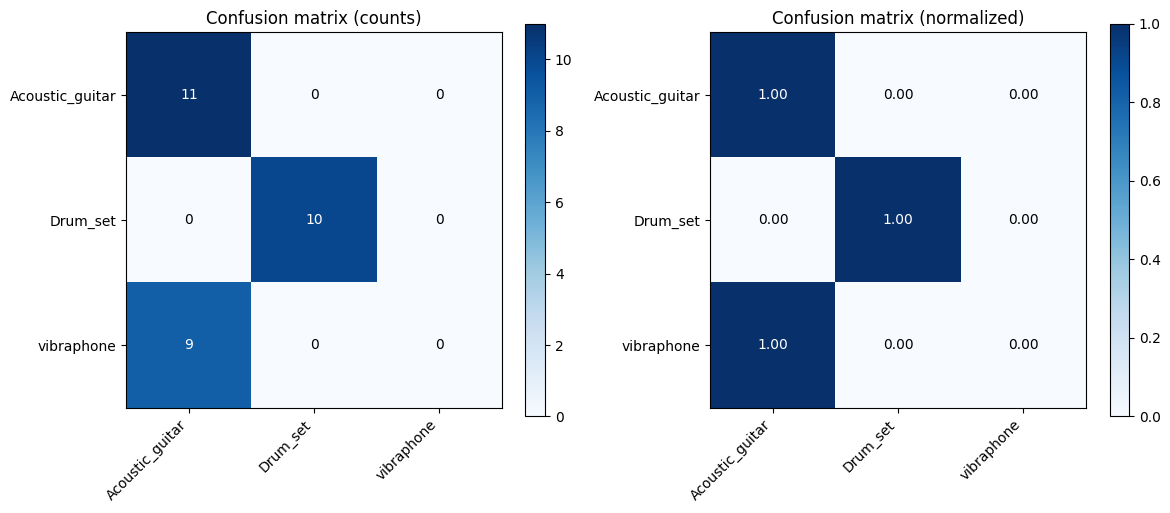

Classification report:
Using in-memory model instance


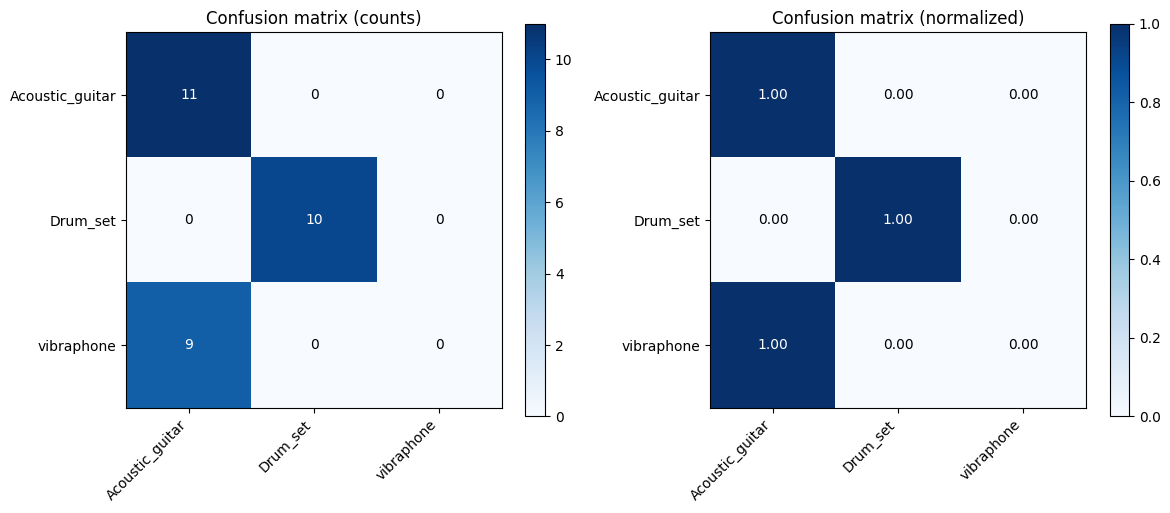

Classification report:
                 precision    recall  f1-score   support

Acoustic_guitar       0.55      1.00      0.71        11
       Drum_set       1.00      1.00      1.00        10
     vibraphone       0.00      0.00      0.00         9

       accuracy                           0.70        30
      macro avg       0.52      0.67      0.57        30
   weighted avg       0.54      0.70      0.59        30



C:\Users\Test\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Test\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Test\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classif

In [24]:
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.models import load_model
import os
import numpy as np

# Confusion matrix and classification report for the trained model

import matplotlib.pyplot as plt

# Predict labels for the test set
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Compute confusion matrix (counts) and normalized version
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-12)  # avoid div by zero

# Plot both count and normalized confusion matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Counts
im0 = axes[0].imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
axes[0].set_title("Confusion matrix (counts)")
plt.colorbar(im0, ax=axes[0])
ticks = np.arange(len(CATEGORIES))
axes[0].set_xticks(ticks); axes[0].set_yticks(ticks)
axes[0].set_xticklabels(CATEGORIES, rotation=45, ha='right')
axes[0].set_yticklabels(CATEGORIES)
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[0].text(j, i, f"{cm[i, j]:d}",
                     ha='center', va='center',
                     color='white' if cm[i, j] > thresh else 'black')

# Normalized
im1 = axes[1].imshow(cm_norm, interpolation='nearest', cmap=plt.cm.Blues, vmin=0, vmax=1)
axes[1].set_title("Confusion matrix (normalized)")
plt.colorbar(im1, ax=axes[1])
axes[1].set_xticks(ticks); axes[1].set_yticks(ticks)
axes[1].set_xticklabels(CATEGORIES, rotation=45, ha='right')
axes[1].set_yticklabels(CATEGORIES)
for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        axes[1].text(j, i, f"{cm_norm[i, j]:.2f}",
                     ha='center', va='center',
                     color='white' if cm_norm[i, j] > 0.5 else 'black')

plt.tight_layout()
plt.show()

# Print classification report
print("Classification report:")
import matplotlib.pyplot as plt

# Use in-memory model instance
if 'model' not in globals():
    raise RuntimeError("No model instance found in memory. Train or load a model before running this cell.")
else:
    print("Using in-memory model instance")

# Predict labels for the test set
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Compute confusion matrix (counts) and normalized version
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-12)  # avoid div by zero

# Plot both count and normalized confusion matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Counts
im0 = axes[0].imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
axes[0].set_title("Confusion matrix (counts)")
plt.colorbar(im0, ax=axes[0])
ticks = np.arange(len(CATEGORIES))
axes[0].set_xticks(ticks); axes[0].set_yticks(ticks)
axes[0].set_xticklabels(CATEGORIES, rotation=45, ha='right')
axes[0].set_yticklabels(CATEGORIES)
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[0].text(j, i, f"{cm[i, j]:d}",
                     ha='center', va='center',
                     color='white' if cm[i, j] > thresh else 'black')

# Normalized
im1 = axes[1].imshow(cm_norm, interpolation='nearest', cmap=plt.cm.Blues, vmin=0, vmax=1)
axes[1].set_title("Confusion matrix (normalized)")
plt.colorbar(im1, ax=axes[1])
axes[1].set_xticks(ticks); axes[1].set_yticks(ticks)
axes[1].set_xticklabels(CATEGORIES, rotation=45, ha='right')
axes[1].set_yticklabels(CATEGORIES)
for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        axes[1].text(j, i, f"{cm_norm[i, j]:.2f}",
                     ha='center', va='center',
                     color='white' if cm_norm[i, j] > 0.5 else 'black')

plt.tight_layout()
plt.show()

# Print classification report
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=CATEGORIES))

Categories: ['Acoustic_guitar', 'Drum_set', 'vibraphone']
Total samples in dataset: 300
Label counts (all): Counter({1: 106, 2: 101, 0: 93})
Label counts (train): Counter({np.int64(1): 96, np.int64(2): 92, np.int64(0): 82})
Label counts (test): Counter({np.int64(0): 11, np.int64(1): 10, np.int64(2): 9})
Predicted class distribution on test set: Counter({np.int64(0): 30})
Mean predicted probability per class: [9.9999386e-01 6.3441039e-06 3.9418968e-08]
First 10 test sample predictions (true, pred, probs):
0 2 0 ['1.000', '0.000', '0.000']
1 0 0 ['1.000', '0.000', '0.000']
2 2 0 ['1.000', '0.000', '0.000']
3 0 0 ['1.000', '0.000', '0.000']
4 1 0 ['1.000', '0.000', '0.000']
5 1 0 ['1.000', '0.000', '0.000']
6 1 0 ['1.000', '0.000', '0.000']
7 1 0 ['1.000', '0.000', '0.000']
8 1 0 ['1.000', '0.000', '0.000']
9 0 0 ['1.000', '0.000', '0.000']
Last train acc: 0.9925925731658936 val_acc: 0.36666667461395264


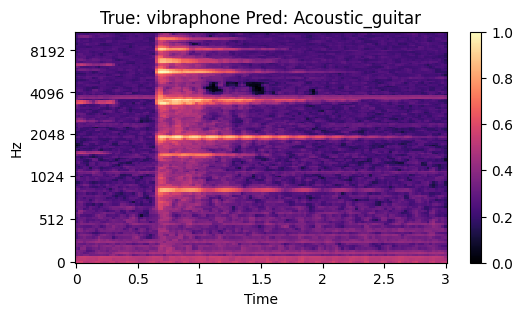

In [18]:
# Diagnostic checks for class balance and predictions
from collections import Counter
import numpy as np

print("Categories:", CATEGORIES)

# Dataset label counts
try:
    print("Total samples in dataset:", len(dataset))
    print("Label counts (all):", Counter([label for _, label, _ in dataset]))
except Exception as e:
    print("Could not compute dataset counts:", e)

# Train/test label counts
try:
    print("Label counts (train):", Counter(y_train))
    print("Label counts (test):", Counter(y_test))
except Exception as e:
    print("Could not compute train/test counts:", e)

# Prediction distribution and probabilities
try:
    y_prob = model.predict(x_test, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    print("Predicted class distribution on test set:", Counter(y_pred))
    print("Mean predicted probability per class:", np.mean(y_prob, axis=0))
    print("First 10 test sample predictions (true, pred, probs):")
    for i in range(min(10, len(y_prob))):
        print(i, y_test[i], y_pred[i], [f"{p:.3f}" for p in y_prob[i]])
except Exception as e:
    print("Prediction step failed:", e)

# Training history quick look
try:
    if 'history' in globals():
        print("Last train acc:", history.history.get('accuracy')[-1], "val_acc:", history.history.get('val_accuracy')[-1])
except Exception as e:
    print("Could not read training history:", e)

# Show one example spectrogram with prediction
try:
    sample_idx = 0
    spec = np.squeeze(x_test[sample_idx])
    import matplotlib.pyplot as plt
    plt.figure(figsize=(6,3))
    librosa.display.specshow(spec, x_axis='time', y_axis='mel', sr=dataset[sample_idx][2] if len(dataset)>sample_idx else None)
    plt.title(f"True: {CATEGORIES[y_test[sample_idx]]} Pred: {CATEGORIES[y_pred[sample_idx]]}")
    plt.colorbar()
    plt.show()
except Exception as e:
    print("Plotting failed:", e)

In [21]:
# Corrected diagnostics (avoid relying on model.input)
from collections import Counter
import numpy as np

eps = 1e-12
# Predictions
y_prob_train = model.predict(x_train, verbose=0)
y_pred_train = np.argmax(y_prob_train, axis=1)

y_prob_test = model.predict(x_test, verbose=0)
y_pred_test = np.argmax(y_prob_test, axis=1)

print("Train predicted distribution:", Counter(y_pred_train))
print("Test predicted distribution:", Counter(y_pred_test))
print("Mean train probs:", np.mean(y_prob_train, axis=0))
print("Mean test probs:", np.mean(y_prob_test, axis=0))

# Approximate logits via log-softmax (monotonic transform)
logits_train_approx = np.log(np.clip(y_prob_train, eps, 1.0))
logits_test_approx = np.log(np.clip(y_prob_test, eps, 1.0))
print("Mean approx logits (train):", np.mean(logits_train_approx, axis=0))
print("Mean approx logits (test):", np.mean(logits_test_approx, axis=0))

# Per-sample statistics to detect normalization issues
train_std_mean = np.mean([s.std() for s in x_train])
test_std_mean = np.mean([s.std() for s in x_test])
print("Mean per-sample std: train", train_std_mean, "test", test_std_mean)
const_train = sum(1 for s in x_train if np.isclose(s.std(), 0.0))
const_test = sum(1 for s in x_test if np.isclose(s.std(), 0.0))
print("Constant samples train/test:", const_train, const_test)

# Try to locate original dataset indices for the first few test samples (small dataset so brute-force is OK)
def find_original_index(sample):
    for idx, (spec, label, sr) in enumerate(dataset):
        if np.allclose(spec, sample):
            return idx
    return None

for i in range(min(5, len(x_test))):
    orig = find_original_index(x_test[i])
    print(f"test idx {i}, orig idx: {orig}, true {y_test[i]} ({CATEGORIES[y_test[i]]}), pred {y_pred_test[i]} ({CATEGORIES[y_pred_test[i]]})")

# Quick note based on earlier bias print:
print('\nConclusion hint:')
print(' - Final-layer biases were small (near zero).')
print(' - The collapse to class 0 is unlikely caused by a large bias; more likely: overfitting or training dynamics (e.g., skewed minibatches, aggressive LR, insufficient regularization).')
print(' - Next: try re-running with class-balanced batches, lower LR, or more regularization; or evaluate the saved checkpoint `best_model.h5` to compare.')

Train predicted distribution: Counter({np.int64(0): 270})
Test predicted distribution: Counter({np.int64(0): 30})
Mean train probs: [9.9999380e-01 6.5137760e-06 4.7776034e-08]
Mean test probs: [9.9999386e-01 6.3441039e-06 3.9418968e-08]
Mean approx logits (train): [-6.5676109e-06 -1.3423469e+01 -1.7206429e+01]
Mean approx logits (test): [-6.3857015e-06 -1.3540304e+01 -1.7393124e+01]
Mean per-sample std: train 0.19079444 test 0.18995704
Constant samples train/test: 0 0
test idx 0, orig idx: 203, true 2 (vibraphone), pred 0 (Acoustic_guitar)
test idx 1, orig idx: 266, true 0 (Acoustic_guitar), pred 0 (Acoustic_guitar)
test idx 2, orig idx: 152, true 2 (vibraphone), pred 0 (Acoustic_guitar)
test idx 3, orig idx: 9, true 0 (Acoustic_guitar), pred 0 (Acoustic_guitar)
test idx 4, orig idx: 233, true 1 (Drum_set), pred 0 (Acoustic_guitar)

Conclusion hint:
 - Final-layer biases were small (near zero).
 - The collapse to class 0 is unlikely caused by a large bias; more likely: overfitting or t

## Validation

You need the library "pyaudio" to test this feature.

    pip install pyaudio
    
    conda install conda-forge::pyaudio

In [ ]:
import pyaudio
import wave

# Configuration parameters
FORMAT = pyaudio.paInt16  # 16-bit resolution
CHANNELS = 1              # Mono recording
RATE = 44100              # Sample rate (44.1kHz is standard)
CHUNK = 1024              # Buffer size
RECORD_SECONDS = 5        # Duration of recording
OUTPUT_FILENAME = "test_recording.wav"

audio = pyaudio.PyAudio()

# Start Recording
stream = audio.open(format=FORMAT, channels=CHANNELS,
                    rate=RATE, input=True,
                    frames_per_buffer=CHUNK)

print("Recording...")

frames = []

for i in range(0, int(RATE / CHUNK * RECORD_SECONDS)):
    data = stream.read(CHUNK)
    frames.append(data)

print("Finished recording.")

# Stop and close the stream
stream.stop_stream()
stream.close()
audio.terminate()

# Save the recorded data as a WAV file 
# (THIS NEEDS TO BE CHANGED SO IT IS STORED IN MEMORY TO BE USED IN REAL TIME)
with wave.open(OUTPUT_FILENAME, 'wb') as wf:
    wf.setnchannels(CHANNELS)
    wf.setsampwidth(audio.get_sample_size(FORMAT))
    wf.setframerate(RATE)
    wf.writeframes(b''.join(frames))

print(f"File saved as {OUTPUT_FILENAME}")

ModuleNotFoundError: No module named 'pyaudio'

# Inputs and Outputs

This is an LED test code

In [ ]:
# This is a test code for the LED

import Jetson.GPIO as GPIO
import time

LED_PIN = 18  # GPIO pin number where the LED is connected

GPIO.setmode(GPIO.BCM)
GPIO.setup(LED_PIN, GPIO.OUT)

try:
    print("LED ON")
    GPIO.output(LED_PIN, GPIO.HIGH)  # Turn LED on
    time.sleep(2)                     # Keep it on for 2 seconds
    print("LED OFF")
    GPIO.output(LED_PIN, GPIO.LOW)   # Turn LED off
finally:

    GPIO.cleanup()  # Clean up GPIO settings
